# MOHAMED RABBANI + DATA ANALYTICS

# OASIS INFOBYTE — TASK 3: DATA CLEANING AND PREPROCESSING OF THE TITANIC DATASET

Track: Data Analytics

Internship: Oasis Infobyte

Objective:  To clean the Titanic dataset by identifying data quality issues, handling missing values, removing duplicate rows, standardising inconsistent values, detecting outliers, correcting data types, and exporting an analysis-ready CSV file.

Tools:  Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook.

### STEP 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### STEP 2: Load Dataset

In [2]:
Titanic_Dataset = pd.read_csv('Titanic_Dataset.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", Titanic_Dataset.shape)


Titanic_Backup = Titanic_Dataset.copy()

Dataset loaded successfully!
Dataset shape: (891, 12)


In [3]:
Titanic_Dataset.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### STEP 3: Data Quality Report (Before)

In [4]:
print("Shape (rows, columns):", Titanic_Dataset.shape)
print("\nData types:\n", Titanic_Dataset.dtypes)

Missing_Column_Value = Titanic_Dataset.isnull().sum()
print("\nMissing values:\n", Missing_Column_Value)

Duplicate_Row_Count = Titanic_Dataset.duplicated().sum()
print("\nDuplicate rows:", Duplicate_Row_Count)

print("Invalid ages (<= 0):", (Titanic_Dataset['Age'] <= 0).sum())
print("Invalid fares (< 0):", (Titanic_Dataset['Fare'] < 0).sum())

Shape (rows, columns): (891, 12)

Data types:
 PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Missing values:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Duplicate rows: 0
Invalid ages (<= 0): 0
Invalid fares (< 0): 0


### Data Quality Findings

- **Missing values:** Age (177), Cabin (687), Embarked (2).
- **Duplicates:** 0 duplicate rows.
- **Value ranges:** No invalid ages (<= 0) or negative fares found.
- **Data type issues:** PassengerId, Survived and Pclass are stored as
  integers but represent an ID and categories, so they need correction.

In [5]:
Titanic_Dataset.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### STEP 4: Remove Duplicates

In [6]:
Duplicates_Before = Titanic_Dataset.duplicated().sum()

Titanic_Dataset = Titanic_Dataset.drop_duplicates()

Duplicates_Removed = Duplicates_Before - Titanic_Dataset.duplicated().sum()

print("Duplicates before cleaning:", Duplicates_Before)
print("Duplicates removed:", Duplicates_Removed)
print("Duplicates after cleaning:", Titanic_Dataset.duplicated().sum())

Duplicates before cleaning: 0
Duplicates removed: 0
Duplicates after cleaning: 0


### STEP 5: Handle Missing Values

* Age: Missing values were filled using the median because it is less affected by extreme values.

* Embarked: Missing values were filled using the mode because it is a categorical column.

* Cabin: The column was dropped because it contains a high proportion of missing values.


These strategies were selected to reduce missing data while preserving as much useful information as possible.

In [7]:
Median_Age = Titanic_Dataset['Age'].median()
Titanic_Dataset['Age'] = Titanic_Dataset['Age'].fillna(Median_Age)

Embarked_Replaced = Titanic_Dataset['Embarked'].mode()[0]
Titanic_Dataset['Embarked'] = Titanic_Dataset['Embarked'].fillna(Embarked_Replaced)

Titanic_Dataset = Titanic_Dataset.drop(columns=['Cabin'])
Titanic_Dataset.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

### STEP 6: Text Standardization

In [8]:
Titanic_Dataset['Sex'] = Titanic_Dataset['Sex'].str.strip().str.title()
Titanic_Dataset['Name'] = Titanic_Dataset['Name'].str.strip()

Titanic_Dataset.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",Male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",Female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",Male,35.0,0,0,373450,8.0500,S


### Standardization Findings

- **Sex:** Values were already consistent (male/female). Converted to
  title case (Male/Female) and trimmed whitespace.
- **Embarked:** Port codes (S, C, Q) were retained without conversion to full port names.
- **Dates:** No date columns exist in this dataset, so no datetime
  conversion was required.

### STEP 7: Outlier Detection and Handling

In [9]:
for Column in ["Age", "Fare"]:

    Q1 = Titanic_Dataset[Column].quantile(0.25)
    Q3 = Titanic_Dataset[Column].quantile(0.75)
    IQR = Q3 - Q1

    Lower_Limit = Q1 - 1.5 * IQR
    Upper_Limit = Q3 + 1.5 * IQR

    Outlier_Count = (
        (Titanic_Dataset[Column] < Lower_Limit) |
        (Titanic_Dataset[Column] > Upper_Limit)
    ).sum()

    print(f"{Column} outliers: {Outlier_Count}")
    print(f"Lower limit: {Lower_Limit:.2f}")
    print(f"Upper limit: {Upper_Limit:.2f}")
    print("-" * 30)

Age outliers: 66
Lower limit: 2.50
Upper limit: 54.50
------------------------------
Fare outliers: 116
Lower limit: -26.72
Upper limit: 65.63
------------------------------


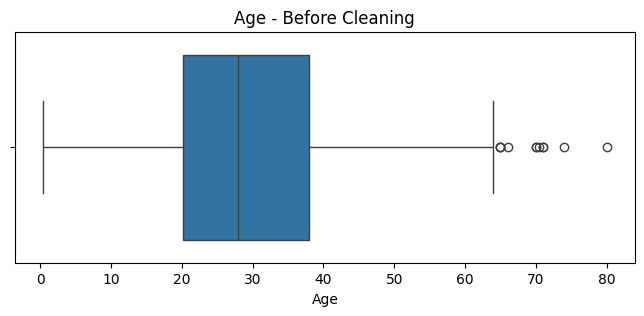

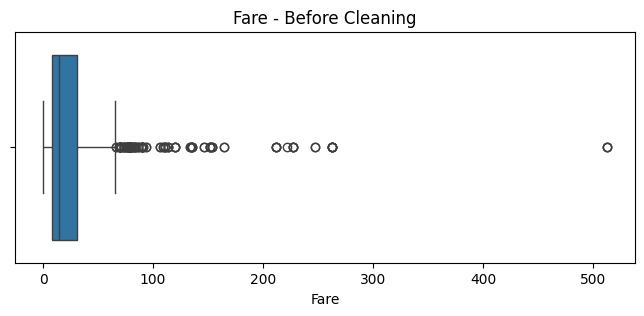

In [10]:
for Column in ["Age", "Fare"]:

    plt.figure(figsize=(8, 3))
    sns.boxplot(x=Titanic_Backup[Column].dropna())
    plt.title(f"{Column} - Before Cleaning")
    plt.xlabel(Column)
    plt.show()

### Observation: Before Cleaning

- **Age:** Most passengers are between 20 and 40 years old. A few passengers
  are above 54.5 years, and these appear as outliers on the right side.
- **Fare:** The distribution is heavily right-skewed. Most fares are low,
  and a few very high fares (maximum 512.33) appear as outliers.

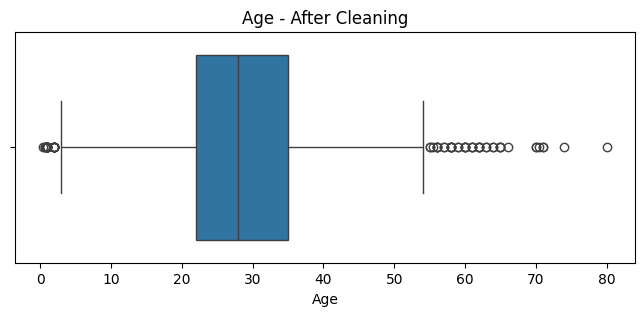

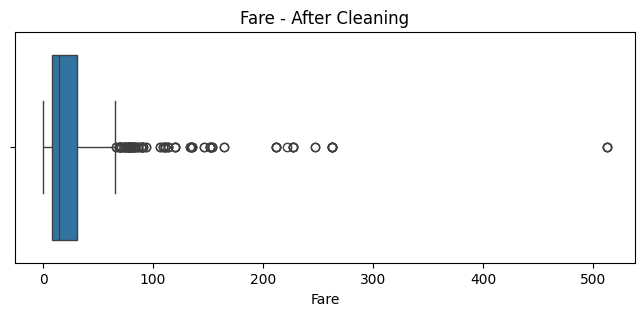

Outlier decision: Retain potentially genuine Age and Fare values.
No values were capped or removed solely because they were outliers.


In [11]:
for Column in ["Age", "Fare"]:

    plt.figure(figsize=(8, 3))
    sns.boxplot(x=Titanic_Dataset[Column].dropna())
    plt.title(f"{Column} - After Cleaning")
    plt.xlabel(Column)
    plt.show()

print("Outlier decision: Retain potentially genuine Age and Fare values.")
print("No values were capped or removed solely because they were outliers.")

### Observation: After Cleaning

- **Age:** The box looks slightly narrower because 177 missing values were
  filled with the median age (28).
- **Fare:** The plot is the same as before, because outliers were retained
  and no values were capped.

### Outlier Decision

The IQR method was used to detect outliers in Age and Fare.

- **Age:** 66 outliers found. Retained, because these are genuine passenger
  ages (infants and elderly passengers).
- **Fare:** 116 outliers found. Retained, because high fares represent
  genuine first-class tickets, not data errors.

No values were capped or removed solely because they were outliers.

### STEP 8: Data Type Correction

In [12]:
Titanic_Dataset['PassengerId'] = Titanic_Dataset['PassengerId'].astype(str)
Titanic_Dataset['Survived'] = Titanic_Dataset['Survived'].astype('category')
Titanic_Dataset['Pclass'] = Titanic_Dataset['Pclass'].astype('category')
Titanic_Dataset.dtypes

PassengerId         str
Survived       category
Pclass         category
Name                str
Sex                 str
Age             float64
SibSp             int64
Parch             int64
Ticket              str
Fare            float64
Embarked            str
dtype: object

### Data Type Decisions

- **PassengerId:** Converted to string, because it is an identifier and
  not used in calculations.
- **Survived, Pclass:** Converted to category, because they represent
  groups and not quantities.
- **Age, Fare:** Kept as float. Age contains fractional values (for example
  0.42 for infants), and Fare is a monetary value.
- **Name, Sex, Ticket, Embarked:** Text columns, stored as string.

### STEP 9: Before vs After Summary

In [13]:
Before_Cleaning = {
    "Rows": Titanic_Backup.shape[0],
    "Columns": Titanic_Backup.shape[1],
    "Total missing values": int(Titanic_Backup.isnull().sum().sum()),
    "Duplicate rows": int(Titanic_Backup.duplicated().sum()),
    "Columns with incorrect dtype": 3
}

After_Cleaning = {
    "Rows": Titanic_Dataset.shape[0],
    "Columns": Titanic_Dataset.shape[1],
    "Total missing values": int(Titanic_Dataset.isnull().sum().sum()),
    "Duplicate rows": int(Titanic_Dataset.duplicated().sum()),
    "Columns with incorrect dtype": 0
}

Before_After_Comparison = pd.DataFrame({
    "Before Cleaning": Before_Cleaning,
    "After Cleaning": After_Cleaning
})

Before_After_Comparison

,Before Cleaning,After Cleaning
Rows,891,891
Columns,12,11
Total missing values,866,0
Duplicate rows,0,0
Columns with incorrect dtype,3,0


### STEP 10: Save Cleaned File

In [14]:
Titanic_Dataset.to_csv("Titanic_Cleaned.csv", index=False)

In [15]:
Cleaned_Dataset = pd.read_csv("Titanic_Cleaned.csv")

print("Shape:", Cleaned_Dataset.shape)
print("Missing values:", Cleaned_Dataset.isnull().sum().sum())
print("Duplicate rows:", Cleaned_Dataset.duplicated().sum())

Cleaned_Dataset.head()

Shape: (891, 11)
Missing values: 0
Duplicate rows: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",Male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",Female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",Male,35.0,0,0,373450,8.0500,S


### Conclusion

- 866 missing values handled: Age (median), Embarked (mode), Cabin (dropped).
- 0 duplicate rows found.
- Text standardized: Sex labels and Embarked port names.
- Outliers in Age and Fare identified using IQR and retained as genuine values.
- PassengerId, Survived and Pclass converted to correct data types.
- Final dataset: 891 rows, 11 columns, 0 missing values, ready for analysis.